# 24B — GeoMAE-Inspired Anomaly Validation
## Masked-center latent correction, intensity-confounding audit, baseline redundancy, and controlled ablation

### Why this notebook exists

NB24 produced a promising result:

- masked center-token **fire reconstruction anomaly** was clearly higher for Emerging-3 than Persistent hotspot events;
- however, the unmasked latent kNN score behaved in the opposite direction.

The reason may be methodological: the NB24 latent representation was computed with the
**observed center token still visible**.

This notebook therefore does four validation tasks before GeoMAE-inspired anomaly detection is treated as the thesis's main method.

### Validation A — Correct the latent novelty score
Recompute train and August latent representations while **force-masking the current center token**.

### Validation B — Fire-intensity confounding
Check whether reconstruction anomaly is simply a proxy for:
- fire count;
- FRP;
- large/intense fire events.

We decompose reconstruction error into:
- fire-presence reconstruction error;
- fire-count reconstruction error;
- FRP reconstruction error.

Then we calculate an exploratory intensity-adjusted reconstruction score.

### Validation C — Redundancy with hand-crafted anomaly
Compare the learned score against:
- history anomaly from NB23C;
- environmental anomaly from NB23C.

The goal is not to prove one score is "better" without ground-truth anomaly labels.
The goal is to test whether the learned representation contains **non-identical information**.

### Validation D — Controlled ablation
Train three small masked models under the same training setup:

1. `T_FIRE`
   - temporal context only;
   - center cell across 7 days;
   - fire channels only.

2. `ST_FIRE`
   - 7 days × 3×3 spatial neighborhood;
   - fire channels only.

3. `ST_FIRE_WEATHER`
   - 7 days × 3×3 spatial neighborhood;
   - fire + weather channels.

This directly tests whether:
- spatial context adds anything beyond local temporal persistence;
- weather adds anything beyond spatiotemporal fire context.

---

## Interpretation boundary

This notebook validates **hotspot anomaly representation**.

It does NOT identify:
- human ignition,
- intentional burning,
- illegal burning,
- plantation clearing,
- cigarette ignition,
- or natural ignition.

In [30]:
# 1. Imports

from pathlib import Path
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LinearRegression

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 320)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cpu


In [31]:
# 2. Resolve project root and NB24 outputs

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    ckpt = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    data = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    if ckpt.exists() and data.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the NB24 model checkpoint and regional 0.25° dataset. "
        "Run NB24 successfully first."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NB24_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
)

CHECKPOINT_PATH = (
    NB24_DIR
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB24_SCORE_PATH = (
    NB24_DIR
    / "exports"
    / "august_geomae_scores_all_cells.csv"
)

NB23C_POSITIVE_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
    / "exports"
    / "august_positive_refined_anomaly.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_anomaly_validation"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
ABLATION_MODEL_DIR = RESULT_DIR / "ablation_models"

for p in [
    RESULT_DIR,
    EXPORT_DIR,
    FIGURE_DIR,
    ABLATION_MODEL_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("CHECKPOINT_PATH:", CHECKPOINT_PATH)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
CHECKPOINT_PATH: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\models\geomae_inspired_encoder.pt
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_anomaly_validation\t2


In [32]:
# 3. Load NB24 checkpoint robustly

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

print("Checkpoint keys:")
print(sorted(checkpoint.keys()))

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v in checkpoint[
        "feature_mean"
    ].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v in checkpoint[
        "feature_std"
    ].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint[
        "spatial_offsets"
    ]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

MASK_RATIO = float(
    checkpoint["mask_ratio"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

DEV_START = pd.Timestamp("2026-08-01")
DEV_END = pd.Timestamp("2026-08-31")

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

print()
print("TOKEN_FEATURES:", TOKEN_FEATURES)
print("TEMPORAL_DAYS:", TEMPORAL_DAYS)
print("N_SPATIAL:", N_SPATIAL)
print("N_TOKENS:", N_TOKENS)
print("CENTER_TOKEN_INDEX:", CENTER_TOKEN_INDEX)
print("PRETRAIN_END:", PRETRAIN_END.date())

Checkpoint keys:
['center_token_index', 'feature_mean', 'feature_std', 'mask_ratio', 'model_state_dict', 'pretrain_end', 'spatial_offsets', 'temporal_days', 'token_features']

TOKEN_FEATURES: ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
TEMPORAL_DAYS: 7
N_SPATIAL: 9
N_TOKENS: 63
CENTER_TOKEN_INDEX: 58
PRETRAIN_END: 2026-07-31


In [33]:
# 4. Load regional dataset and recreate NB24 fire transforms

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(
        ["date", "cell_id"]
    )
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

missing_features = [
    c
    for c in TOKEN_FEATURES
    if c not in df.columns
]

if missing_features:
    raise ValueError(
        "Dataset is missing NB24 checkpoint features:\n"
        + "\n".join(missing_features)
    )

for feature in TOKEN_FEATURES:
    df[f"z__{feature}"] = (
        (
            df[feature]
            - FEATURE_MEAN[feature]
        )
        / FEATURE_STD[feature]
    )

Z_FEATURES = [
    f"z__{c}"
    for c in TOKEN_FEATURES
]

df["token_valid"] = (
    df[Z_FEATURES]
    .notna()
    .all(axis=1)
)

FIRE_TOKEN_FEATURES = [
    "fire_active",
    "fire_count_log1p",
    "frp_sum_log1p",
]

FIRE_FEATURE_INDICES = [
    TOKEN_FEATURES.index(c)
    for c in FIRE_TOKEN_FEATURES
]

ENV_FEATURE_INDICES = [
    i
    for i, c in enumerate(TOKEN_FEATURES)
    if c not in FIRE_TOKEN_FEATURES
]

print("Rows:", len(df))
print("Nodes:", df["cell_id"].nunique())
print("Fire feature indices:", FIRE_FEATURE_INDICES)
print("Environment feature count:", len(ENV_FEATURE_INDICES))

Rows: 16625
Nodes: 133
Fire feature indices: [10, 11, 12]
Environment feature count: 10


# PART A — Rebuild exactly the same 7-day × 3×3 patches

This must match NB24 so that the saved encoder weights remain valid.

In [34]:
# 5. Coordinate lookup

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

z_matrix = (
    work[Z_FEATURES]
    .to_numpy(
        dtype=np.float32
    )
)

valid_vector = (
    work["token_valid"]
    .to_numpy(
        dtype=bool
    )
)

CENTER_SPATIAL_INDEX = (
    SPATIAL_OFFSETS.index(
        (0, 0)
    )
)

print("Lookup rows:", len(row_lookup))
print("CENTER_SPATIAL_INDEX:", CENTER_SPATIAL_INDEX)

Lookup rows: 16625
CENTER_SPATIAL_INDEX: 4


In [35]:
# 6. Patch builder

def build_patch(
    center_date,
    center_lat,
    center_lon,
):
    center_date = pd.Timestamp(
        center_date
    )

    x = np.zeros(
        (
            N_TOKENS,
            len(Z_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            center_date
            - pd.Timedelta(
                days=day_back
            )
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = z_matrix[idx]
                valid[token_idx] = True

            token_idx += 1

    return x, valid

In [36]:
# 7. Materialize samples

min_date = (
    pd.Timestamp(
        work["date"].min()
    )
    + pd.Timedelta(
        days=TEMPORAL_DAYS - 1
    )
)

sample_meta = (
    work[
        work["date"] >= min_date
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_active",
            "fire_count",
            "frp_sum",
            "fire_count_log1p",
            "frp_sum_log1p",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

patches = []
valid_masks = []
kept_meta = []

for row in sample_meta.itertuples(
    index=False
):
    x, valid = build_patch(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)

    kept_meta.append(
        row._asdict()
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

META = pd.DataFrame(
    kept_meta
)

train_idx = np.flatnonzero(
    META["date"]
    .le(PRETRAIN_END)
    .to_numpy()
)

aug_idx = np.flatnonzero(
    META["date"]
    .between(
        DEV_START,
        DEV_END,
    )
    .to_numpy()
)

print("X:", X.shape)
print("VALID:", VALID.shape)
print("Train samples:", len(train_idx))
print("August samples:", len(aug_idx))

X: (15827, 63, 13)
VALID: (15827, 63)
Train samples: 10507
August samples: 4123


# PART B — Restore the exact NB24 model

In [37]:
# 8. Dataset helper

class PatchDataset(Dataset):
    def __init__(
        self,
        X,
        valid,
        indices,
    ):
        self.X = X
        self.valid = valid
        self.indices = np.asarray(
            indices
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.from_numpy(
                self.valid[idx]
            ),
            idx,
        )

In [38]:
# 9. NB24 model class

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            d_model,
        )

        self.space_embedding = nn.Embedding(
            N_SPATIAL,
            d_model,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        token_time = []
        token_space = []

        for t in range(TEMPORAL_DAYS):
            for s in range(N_SPATIAL):
                token_time.append(t)
                token_space.append(s)

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(x)

        if mask_positions is not None:
            mask_embed = (
                self.mask_token.expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_embed,
                h,
            )

        positional = (
            self.time_embedding(
                self.token_time
            )
            + self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = self.reconstruction_head(
            h
        )

        return recon, h

In [39]:
# 10. Infer architecture dimensions from checkpoint and restore model

state = checkpoint[
    "model_state_dict"
]

D_MODEL = int(
    state[
        "input_proj.weight"
    ].shape[0]
)

DIM_FEEDFORWARD = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

layer_numbers = []

for key in state:
    if key.startswith(
        "encoder.layers."
    ):
        parts = key.split(".")
        if len(parts) > 2:
            try:
                layer_numbers.append(
                    int(parts[2])
                )
            except ValueError:
                pass

NUM_LAYERS = (
    max(layer_numbers) + 1
    if layer_numbers
    else 2
)

# NB24 used four attention heads.
NHEAD = 4

model = SpatiotemporalMaskedEncoder(
    n_features=len(TOKEN_FEATURES),
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
).to(DEVICE)

model.load_state_dict(
    state,
    strict=True,
)

model.eval()

print("Restored NB24 model.")
print("D_MODEL:", D_MODEL)
print("NHEAD:", NHEAD)
print("NUM_LAYERS:", NUM_LAYERS)
print("DIM_FEEDFORWARD:", DIM_FEEDFORWARD)

Restored NB24 model.
D_MODEL: 64
NHEAD: 4
NUM_LAYERS: 2
DIM_FEEDFORWARD: 128


# PART C — Validation A: masked-center latent novelty

NB24's original latent kNN embedding used the observed center token.

Here, both:
- May–July training reference embeddings;
- August embeddings

are generated while the **current center token is masked**.

Therefore the latent representation must summarize context rather than directly reading the
observed current fire state.

In [40]:
# 11. Masked-center latent encoder

@torch.no_grad()
def encode_center_masked(
    indices,
    batch_size=256,
):
    dataset = PatchDataset(
        X,
        VALID,
        indices,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    embeddings = []
    sample_indices = []

    model.eval()

    for x_batch, valid_batch, idx_batch in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        center_mask = torch.zeros_like(
            valid_batch
        )

        center_mask[
            :,
            CENTER_TOKEN_INDEX,
        ] = True

        center_mask = (
            center_mask
            & valid_batch
        )

        latent = model.encode(
            x_batch,
            valid_batch,
            mask_positions=center_mask,
        )

        center_latent = (
            latent[
                :,
                CENTER_TOKEN_INDEX,
                :
            ]
            .detach()
            .cpu()
            .numpy()
        )

        embeddings.append(
            center_latent
        )

        sample_indices.extend(
            idx_batch.numpy()
            .astype(int)
            .tolist()
        )

    return (
        np.concatenate(
            embeddings,
            axis=0,
        ),
        np.asarray(
            sample_indices,
        ),
    )

In [41]:
# 12. Compute corrected masked-center kNN novelty

train_masked_embeddings, train_masked_idx = (
    encode_center_masked(
        train_idx
    )
)

aug_masked_embeddings, aug_masked_idx = (
    encode_center_masked(
        aug_idx
    )
)

K_NEIGHBORS = 10

knn_masked = NearestNeighbors(
    n_neighbors=K_NEIGHBORS,
    metric="euclidean",
    n_jobs=-1,
)

knn_masked.fit(
    train_masked_embeddings
)

masked_distances, _ = (
    knn_masked.kneighbors(
        aug_masked_embeddings
    )
)

masked_knn_distance = (
    masked_distances.mean(
        axis=1
    )
)

masked_latent_scores = pd.DataFrame({
    "sample_index": aug_masked_idx,
    "masked_center_knn_distance": masked_knn_distance,
})

masked_latent_scores = (
    META.iloc[
        masked_latent_scores[
            "sample_index"
        ].to_numpy()
    ]
    .reset_index()
    .rename(
        columns={
            "index": "sample_index"
        }
    )
    .merge(
        masked_latent_scores,
        on="sample_index",
        how="left",
        validate="one_to_one",
    )
)

masked_latent_scores[
    "masked_center_knn_distance__day_rank"
] = (
    masked_latent_scores
    .groupby(
        "date"
    )[
        "masked_center_knn_distance"
    ]
    .rank(
        pct=True,
        ascending=True,
        method="average",
    )
)

print(
    "Masked-center August embeddings:",
    len(masked_latent_scores),
)

Masked-center August embeddings: 4123


In [42]:
# 13. Load original NB24 scores for direct comparison

if not NB24_SCORE_PATH.exists():
    raise FileNotFoundError(
        "NB24 august_geomae_scores_all_cells.csv not found."
    )

old_scores = pd.read_csv(
    NB24_SCORE_PATH,
    parse_dates=["date"],
)

compare_latent = (
    old_scores[
        [
            "date",
            "cell_id",
            "mae_fire_reconstruction_error",
            "mae_fire_reconstruction_error__day_rank",
            "embedding_knn_distance",
            "embedding_knn_distance__day_rank",
        ]
    ]
    .merge(
        masked_latent_scores[
            [
                "date",
                "cell_id",
                "masked_center_knn_distance",
                "masked_center_knn_distance__day_rank",
            ]
        ],
        on=[
            "date",
            "cell_id",
        ],
        how="inner",
        validate="one_to_one",
    )
)

rho_old_new, _ = spearmanr(
    compare_latent[
        "embedding_knn_distance__day_rank"
    ],
    compare_latent[
        "masked_center_knn_distance__day_rank"
    ],
)

rho_recon_masked_latent, _ = (
    spearmanr(
        compare_latent[
            "mae_fire_reconstruction_error__day_rank"
        ],
        compare_latent[
            "masked_center_knn_distance__day_rank"
        ],
    )
)

print(
    "Old-unmasked vs corrected-masked latent rank Spearman:",
    round(float(rho_old_new), 4),
)

print(
    "Reconstruction vs corrected-masked latent rank Spearman:",
    round(
        float(
            rho_recon_masked_latent
        ),
        4,
    ),
)

Old-unmasked vs corrected-masked latent rank Spearman: 0.8115
Reconstruction vs corrected-masked latent rank Spearman: 0.3791


# PART D — Positive-event evaluation against Emerging/Persistent groups

NB23C group labels are used **only for post-hoc evaluation**.

They were not used to train NB24.

In [43]:
# 14. Load NB23C August positive events and merge corrected scores

if not NB23C_POSITIVE_PATH.exists():
    raise FileNotFoundError(
        "NB23C positive-event export not found."
    )

nb23c_pos = pd.read_csv(
    NB23C_POSITIVE_PATH,
    parse_dates=[
        "date",
        "event_date",
    ],
)

positive_model_scores = (
    compare_latent
    .merge(
        META[
            [
                "date",
                "cell_id",
                "fire_active",
                "fire_count",
                "frp_sum",
                "fire_count_log1p",
                "frp_sum_log1p",
            ]
        ],
        on=[
            "date",
            "cell_id",
        ],
        how="left",
        validate="one_to_one",
    )
)

positive_model_scores = (
    positive_model_scores[
        positive_model_scores[
            "fire_active"
        ].eq(1)
    ]
    .copy()
    .rename(
        columns={
            "date": "event_date"
        }
    )
)

analysis_positive = (
    nb23c_pos
    .merge(
        positive_model_scores,
        on=[
            "event_date",
            "cell_id",
        ],
        how="inner",
    )
)

print("Merged positive events:", len(analysis_positive))
print(
    analysis_positive[
        "research_group"
    ].value_counts()
)

Merged positive events: 2066
research_group
Persistent    1849
Emerging-3     217
Name: count, dtype: int64


In [44]:
# 15. Corrected latent group summary

latent_group_summary = (
    analysis_positive
    .groupby(
        "research_group"
    )
    .agg(
        events=(
            "cell_id",
            "size",
        ),
        reconstruction_rank_mean=(
            "mae_fire_reconstruction_error__day_rank",
            "mean",
        ),
        reconstruction_rank_median=(
            "mae_fire_reconstruction_error__day_rank",
            "median",
        ),
        old_unmasked_latent_rank_median=(
            "embedding_knn_distance__day_rank",
            "median",
        ),
        corrected_masked_latent_rank_mean=(
            "masked_center_knn_distance__day_rank",
            "mean",
        ),
        corrected_masked_latent_rank_median=(
            "masked_center_knn_distance__day_rank",
            "median",
        ),
    )
    .reset_index()
)

display(latent_group_summary)

,research_group,events,reconstruction_rank_mean,reconstruction_rank_median,old_unmasked_latent_rank_median,corrected_masked_latent_rank_mean,corrected_masked_latent_rank_median
0,Emerging-3,217,0.77402,0.819549,0.578947,0.375212,0.353383
1,Persistent,1849,0.58900,0.616541,0.729323,0.641863,0.691729


In [45]:
# 16. Generic date-block bootstrap helper

def date_block_bootstrap_median_diff(
    df,
    value_col,
    date_col="event_date",
    group_col="research_group",
    group_a="Emerging-3",
    group_b="Persistent",
    n_boot=2000,
    seed=42,
):
    rng = np.random.default_rng(
        seed
    )

    dates = np.array(
        sorted(
            df[
                date_col
            ].dropna()
            .unique()
        )
    )

    a = df.loc[
        df[group_col].eq(
            group_a
        ),
        value_col,
    ].dropna()

    b = df.loc[
        df[group_col].eq(
            group_b
        ),
        value_col,
    ].dropna()

    if len(a) == 0 or len(b) == 0:
        return None

    observed = float(
        a.median()
        - b.median()
    )

    boot = []

    for _ in range(
        n_boot
    ):
        sampled_dates = rng.choice(
            dates,
            size=len(dates),
            replace=True,
        )

        pieces = [
            df[
                df[date_col].eq(d)
            ]
            for d in sampled_dates
        ]

        sample = pd.concat(
            pieces,
            ignore_index=True,
        )

        sa = sample.loc[
            sample[group_col].eq(
                group_a
            ),
            value_col,
        ].dropna()

        sb = sample.loc[
            sample[group_col].eq(
                group_b
            ),
            value_col,
        ].dropna()

        if len(sa) and len(sb):
            boot.append(
                float(
                    sa.median()
                    - sb.median()
                )
            )

    lo, hi = np.quantile(
        boot,
        [0.025, 0.975],
    )

    return {
        "score": value_col,
        "observed_median_difference": observed,
        "bootstrap_2.5%": float(lo),
        "bootstrap_97.5%": float(hi),
        "bootstrap_samples": len(boot),
    }

In [46]:
# 17. Bootstrap corrected latent vs reconstruction

bootstrap_rows = []

for score in [
    "mae_fire_reconstruction_error__day_rank",
    "embedding_knn_distance__day_rank",
    "masked_center_knn_distance__day_rank",
]:
    result = (
        date_block_bootstrap_median_diff(
            analysis_positive,
            score,
        )
    )

    if result is not None:
        bootstrap_rows.append(
            result
        )

corrected_latent_bootstrap = pd.DataFrame(
    bootstrap_rows
)

display(corrected_latent_bootstrap)

,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mae_fire_reconstruction_error__day_rank,0.203008,0.180451,0.225564,2000
1,embedding_knn_distance__day_rank,-0.150376,-0.248214,-0.090226,2000
2,masked_center_knn_distance__day_rank,-0.338346,-0.417293,-0.274436,2000


# PART E — Validation B: fire-intensity confounding

The NB24 fire reconstruction score averaged:

- `fire_active`
- `log(1 + fire_count)`
- `log(1 + FRP)`

A strong anomaly score is only interesting if it is not merely saying:

> larger fire = larger reconstruction error.

We therefore calculate each center-channel reconstruction error separately.

In [47]:
# 18. Center reconstruction component errors

@torch.no_grad()
def center_component_errors(
    indices,
    batch_size=256,
):
    dataset = PatchDataset(
        X,
        VALID,
        indices,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for x_batch, valid_batch, idx_batch in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        center_mask = torch.zeros_like(
            valid_batch
        )

        center_mask[
            :,
            CENTER_TOKEN_INDEX,
        ] = True

        center_mask = (
            center_mask
            & valid_batch
        )

        prediction, _ = model(
            x_batch,
            valid_batch,
            center_mask,
        )

        true_center = x_batch[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        pred_center = prediction[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        sq = (
            pred_center
            - true_center
        ) ** 2

        presence_err = (
            sq[
                :,
                FIRE_FEATURE_INDICES[0]
            ]
            .detach()
            .cpu()
            .numpy()
        )

        count_err = (
            sq[
                :,
                FIRE_FEATURE_INDICES[1]
            ]
            .detach()
            .cpu()
            .numpy()
        )

        frp_err = (
            sq[
                :,
                FIRE_FEATURE_INDICES[2]
            ]
            .detach()
            .cpu()
            .numpy()
        )

        for idx, pe, ce, fe in zip(
            idx_batch.numpy(),
            presence_err,
            count_err,
            frp_err,
        ):
            rows.append({
                "sample_index": int(idx),
                "presence_reconstruction_error": float(pe),
                "count_reconstruction_error": float(ce),
                "frp_reconstruction_error": float(fe),
            })

    return pd.DataFrame(
        rows
    )

In [48]:
# 19. Score August component errors

component_scores = (
    center_component_errors(
        aug_idx
    )
)

component_scores = (
    META.iloc[
        component_scores[
            "sample_index"
        ].to_numpy()
    ]
    .reset_index()
    .rename(
        columns={
            "index": "sample_index"
        }
    )
    .merge(
        component_scores,
        on="sample_index",
        how="left",
        validate="one_to_one",
    )
)

for col in [
    "presence_reconstruction_error",
    "count_reconstruction_error",
    "frp_reconstruction_error",
]:
    component_scores[
        col + "__day_rank"
    ] = (
        component_scores
        .groupby(
            "date"
        )[col]
        .rank(
            pct=True,
            ascending=True,
            method="average",
        )
    )

display(
    component_scores.head()
)

,sample_index,date,cell_id,grid_lat,grid_lon,fire_active,fire_count,frp_sum,fire_count_log1p,frp_sum_log1p,presence_reconstruction_error,count_reconstruction_error,frp_reconstruction_error,presence_reconstruction_error__day_rank,count_reconstruction_error__day_rank,frp_reconstruction_error__day_rank
0,10507,2026-08-01,regional025_10_22,-1.875,113.625,0,0.0,0.0,0.0,0.0,0.000158,0.002931,0.000788,0.007519,0.263158,0.097744
1,10508,2026-08-01,regional025_10_23,-1.875,113.875,0,0.0,0.0,0.0,0.0,0.061909,0.017928,0.033803,0.375940,0.383459,0.375940
2,10509,2026-08-01,regional025_10_24,-1.875,114.125,0,0.0,0.0,0.0,0.0,0.035704,0.012798,0.028310,0.315789,0.345865,0.338346
3,10510,2026-08-01,regional025_10_25,-1.875,114.375,0,0.0,0.0,0.0,0.0,0.182417,0.129463,0.168365,0.503759,0.548872,0.526316
4,10511,2026-08-01,regional025_10_26,-1.875,114.625,0,0.0,0.0,0.0,0.0,0.143837,0.079847,0.119505,0.466165,0.488722,0.511278


In [49]:
# 20. Merge component errors into positive-event table

positive_components = (
    component_scores[
        component_scores[
            "fire_active"
        ].eq(1)
    ]
    .copy()
    .rename(
        columns={
            "date": "event_date"
        }
    )
)

component_cols = [
    "event_date",
    "cell_id",
    "presence_reconstruction_error",
    "presence_reconstruction_error__day_rank",
    "count_reconstruction_error",
    "count_reconstruction_error__day_rank",
    "frp_reconstruction_error",
    "frp_reconstruction_error__day_rank",
]

analysis_positive = (
    analysis_positive
    .merge(
        positive_components[
            component_cols
        ],
        on=[
            "event_date",
            "cell_id",
        ],
        how="left",
        validate="one_to_one",
    )
)

In [50]:
# 21. Intensity correlation audit

intensity_audit_rows = []

for score in [
    "mae_fire_reconstruction_error__day_rank",
    "presence_reconstruction_error__day_rank",
    "count_reconstruction_error__day_rank",
    "frp_reconstruction_error__day_rank",
]:
    for intensity in [
        "fire_count_log1p",
        "frp_sum_log1p",
    ]:
        valid = (
            analysis_positive[
                [score, intensity]
            ]
            .dropna()
        )

        rho, p = spearmanr(
            valid[score],
            valid[intensity],
        )

        intensity_audit_rows.append({
            "anomaly_score": score,
            "intensity_variable": intensity,
            "spearman_rho": float(rho),
            "p_value": float(p),
            "n": len(valid),
        })

intensity_correlation_audit = pd.DataFrame(
    intensity_audit_rows
)

display(intensity_correlation_audit)

,anomaly_score,intensity_variable,spearman_rho,p_value,n
0,mae_fire_reconstruction_error__day_rank,fire_count_log1p,-0.049150,2.547997e-02,2066
1,mae_fire_reconstruction_error__day_rank,frp_sum_log1p,0.068605,1.807897e-03,2066
2,presence_reconstruction_error__day_rank,fire_count_log1p,-0.671274,9.450489e-271,2066
3,presence_reconstruction_error__day_rank,frp_sum_log1p,-0.560304,4.176553e-171,2066
4,count_reconstruction_error__day_rank,fire_count_log1p,0.229248,4.834060e-26,2066
5,count_reconstruction_error__day_rank,frp_sum_log1p,0.239844,2.030301e-28,2066
6,frp_reconstruction_error__day_rank,fire_count_log1p,0.050539,2.160614e-02,2066
7,frp_reconstruction_error__day_rank,frp_sum_log1p,0.219915,4.795569e-24,2066


In [51]:
# 22. Exploratory intensity-adjusted reconstruction anomaly

# This is NOT a replacement primary score.
# It is a diagnostic: remove the linear association of day-ranked reconstruction anomaly
# with same-event log fire count and log FRP.

intensity_model_df = (
    analysis_positive[
        [
            "mae_fire_reconstruction_error__day_rank",
            "fire_count_log1p",
            "frp_sum_log1p",
        ]
    ]
    .dropna()
)

X_intensity = intensity_model_df[
    [
        "fire_count_log1p",
        "frp_sum_log1p",
    ]
].to_numpy()

y_recon = intensity_model_df[
    "mae_fire_reconstruction_error__day_rank"
].to_numpy()

intensity_reg = LinearRegression()

intensity_reg.fit(
    X_intensity,
    y_recon,
)

predicted_by_intensity = (
    intensity_reg.predict(
        X_intensity
    )
)

residual = (
    y_recon
    - predicted_by_intensity
)

analysis_positive[
    "reconstruction_intensity_residual"
] = np.nan

analysis_positive.loc[
    intensity_model_df.index,
    "reconstruction_intensity_residual",
] = residual

print(
    "Linear intensity model R²:",
    round(
        float(
            intensity_reg.score(
                X_intensity,
                y_recon,
            )
        ),
        4,
    ),
)

Linear intensity model R²: 0.0183


In [52]:
# 23. Does Emerging remain different after intensity adjustment?

intensity_adjusted_summary = (
    analysis_positive
    .groupby(
        "research_group"
    )
    .agg(
        events=(
            "cell_id",
            "size",
        ),
        raw_reconstruction_median=(
            "mae_fire_reconstruction_error__day_rank",
            "median",
        ),
        presence_error_rank_median=(
            "presence_reconstruction_error__day_rank",
            "median",
        ),
        intensity_residual_median=(
            "reconstruction_intensity_residual",
            "median",
        ),
    )
    .reset_index()
)

display(
    intensity_adjusted_summary
)

intensity_residual_bootstrap = (
    date_block_bootstrap_median_diff(
        analysis_positive,
        "reconstruction_intensity_residual",
    )
)

display(
    pd.DataFrame(
        [
            intensity_residual_bootstrap
        ]
    )
)

,research_group,events,raw_reconstruction_median,presence_error_rank_median,intensity_residual_median
0,Emerging-3,217,0.819549,0.924812,0.216147
1,Persistent,1849,0.616541,0.458647,0.009919


,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,reconstruction_intensity_residual,0.206227,0.178318,0.232994,2000


In [53]:
# 24. Intensity-stratified descriptive check

analysis_positive[
    "combined_intensity"
] = (
    analysis_positive[
        [
            "fire_count_log1p",
            "frp_sum_log1p",
        ]
    ]
    .mean(axis=1)
)

try:
    analysis_positive[
        "intensity_quartile"
    ] = pd.qcut(
        analysis_positive[
            "combined_intensity"
        ],
        q=4,
        duplicates="drop",
    )
except ValueError:
    analysis_positive[
        "intensity_quartile"
    ] = "all"

intensity_stratified = (
    analysis_positive
    .groupby(
        [
            "intensity_quartile",
            "research_group",
        ],
        observed=True,
    )
    .agg(
        events=(
            "cell_id",
            "size",
        ),
        recon_rank_median=(
            "mae_fire_reconstruction_error__day_rank",
            "median",
        ),
        presence_rank_median=(
            "presence_reconstruction_error__day_rank",
            "median",
        ),
    )
    .reset_index()
)

display(
    intensity_stratified
)

,intensity_quartile,research_group,events,recon_rank_median,presence_rank_median
0,"(0.492, 1.514]",Emerging-3,110,0.763158,0.939850
1,"(0.492, 1.514]",Persistent,407,0.654135,0.766917
2,"(1.514, 2.358]",Emerging-3,78,0.864662,0.909774
3,"(1.514, 2.358]",Persistent,438,0.578947,0.631579
4,"(2.358, 3.355]",Emerging-3,26,0.966165,0.906015
5,"(2.358, 3.355]",Persistent,490,0.458647,0.398496
6,"(3.355, 7.256]",Emerging-3,3,0.939850,0.593985
7,"(3.355, 7.256]",Persistent,514,0.680451,0.161654


# PART F — Validation C: redundancy vs hand-crafted anomaly scores

No true anomaly ground truth exists.

Therefore we do NOT claim a "winner".

We instead ask:
- how strongly does GeoMAE reconstruction correlate with history anomaly?
- how much does Top-20% membership overlap?
- are there observed hotspot events with high learned anomaly but lower hand-crafted history anomaly?

In [54]:
# 25. Correlation and overlap with NB23C scores

HISTORY_COL = "history_anomaly_day_rank"
ENV_LR_COL = "env_rank__E2_ANTECEDENT_LAND_LR"
ENV_HGB_COL = "env_rank__E3_ANTECEDENT_LAND_HGB"

available_compare_cols = [
    c
    for c in [
        HISTORY_COL,
        ENV_LR_COL,
        ENV_HGB_COL,
        "mae_fire_reconstruction_error__day_rank",
        "masked_center_knn_distance__day_rank",
        "fire_count_log1p",
        "frp_sum_log1p",
    ]
    if c in analysis_positive.columns
]

rank_correlation = (
    analysis_positive[
        available_compare_cols
    ]
    .corr(
        method="spearman"
    )
)

display(
    rank_correlation
)

,history_anomaly_day_rank,env_rank__E2_ANTECEDENT_LAND_LR,env_rank__E3_ANTECEDENT_LAND_HGB,mae_fire_reconstruction_error__day_rank,masked_center_knn_distance__day_rank,fire_count_log1p,frp_sum_log1p
history_anomaly_day_rank,1.000000,0.302712,0.420708,0.150336,-0.442273,-0.597338,-0.476677
env_rank__E2_ANTECEDENT_LAND_LR,0.302712,1.000000,0.378421,0.176171,-0.060145,-0.165067,-0.162102
env_rank__E3_ANTECEDENT_LAND_HGB,0.420708,0.378421,1.000000,0.132670,-0.080083,-0.300210,-0.214506
mae_fire_reconstruction_error__day_rank,0.150336,0.176171,0.132670,1.000000,-0.181140,-0.049150,0.068605
masked_center_knn_distance__day_rank,-0.442273,-0.060145,-0.080083,-0.181140,1.000000,0.234491,0.144605
fire_count_log1p,-0.597338,-0.165067,-0.300210,-0.049150,0.234491,1.000000,0.881979
frp_sum_log1p,-0.476677,-0.162102,-0.214506,0.068605,0.144605,0.881979,1.000000


In [55]:
# 26. Top-20% overlap with hand-crafted history anomaly

TOP_Q = 0.80

geomae_high = (
    analysis_positive[
        "mae_fire_reconstruction_error__day_rank"
    ]
    >= TOP_Q
)

history_high = (
    analysis_positive[
        HISTORY_COL
    ]
    >= TOP_Q
)

intersection = int(
    (
        geomae_high
        & history_high
    ).sum()
)

union = int(
    (
        geomae_high
        | history_high
    ).sum()
)

history_geomae_jaccard = (
    intersection / union
    if union
    else np.nan
)

print(
    "GeoMAE reconstruction vs history Top-20% Jaccard:",
    round(
        float(
            history_geomae_jaccard
        ),
        4,
    ),
)

print(
    "High GeoMAE reconstruction:",
    int(
        geomae_high.sum()
    ),
)

print(
    "High history anomaly:",
    int(
        history_high.sum()
    ),
)

print(
    "Both:",
    intersection,
)

GeoMAE reconstruction vs history Top-20% Jaccard: 0.093
High GeoMAE reconstruction: 604
High history anomaly: 125
Both: 62


In [56]:
analysis_positive = (
    nb23c_pos
    .merge(
        positive_model_scores,
        on=[
            "event_date",
            "cell_id",
        ],
        how="inner",
    )
)

# Fix duplicate columns caused by merge
for col in [
    "fire_count",
    "frp_sum",
    "fire_count_log1p",
    "frp_sum_log1p",
]:
    if col not in analysis_positive.columns:
        candidates = [
            f"{col}_x",
            f"{col}_y",
        ]

        available = [
            c
            for c in candidates
            if c in analysis_positive.columns
        ]

        if available:
            analysis_positive[col] = (
                analysis_positive[
                    available
                ]
                .bfill(axis=1)
                .iloc[:, 0]
            )

print(
    "Merged positive events:",
    len(analysis_positive),
)

print(
    analysis_positive[
        "research_group"
    ].value_counts()
)

print()
print("Fire columns available:")
print(
    [
        c
        for c in analysis_positive.columns
        if "fire_count" in c
        or "frp_sum" in c
    ]
)

Merged positive events: 2066
research_group
Persistent    1849
Emerging-3     217
Name: count, dtype: int64

Fire columns available:
['fire_count_x', 'frp_sum_x', 'fire_count_lag1', 'fire_count_lag3', 'fire_count_lag7', 'frp_sum_lag1', 'frp_sum_lag3', 'frp_sum_lag7', 'fire_count_roll3', 'frp_sum_roll3', 'fire_count_roll7', 'frp_sum_roll7', 'fire_count_y', 'frp_sum_y', 'fire_count_log1p', 'frp_sum_log1p', 'fire_count', 'frp_sum']


# PART G — Validation D: controlled ablation

This section trains three intentionally small models.

The goal is **not** hyperparameter optimization.

All variants use:
- same chronological pretraining period;
- same mask ratio;
- same random seed;
- same hidden dimension;
- same number of transformer layers;
- same number of epochs.

The only controlled changes are the available context/features.

In [57]:
# 28. Ablation settings

RUN_ABLATION = True
FORCE_RETRAIN_ABLATION = False

ABLATION_EPOCHS = 8
ABLATION_BATCH_SIZE = 128
ABLATION_D_MODEL = 48
ABLATION_NHEAD = 4
ABLATION_NUM_LAYERS = 2
ABLATION_FF = 96
ABLATION_LR = 1e-3
ABLATION_WEIGHT_DECAY = 1e-4

print(
    "RUN_ABLATION:",
    RUN_ABLATION,
)

print(
    "Ablation epochs:",
    ABLATION_EPOCHS,
)

RUN_ABLATION: True
Ablation epochs: 8


In [58]:
# 29. Generic masked Transformer for controlled ablation

class GenericMaskedTransformer(nn.Module):
    def __init__(
        self,
        n_features,
        token_time,
        token_space,
        n_time,
        n_space,
        d_model=48,
        nhead=4,
        num_layers=2,
        dim_feedforward=96,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = nn.Embedding(
            n_time,
            d_model,
        )

        self.space_embedding = nn.Embedding(
            n_space,
            d_model,
        )

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.encoder = nn.TransformerEncoder(
            layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

        nn.init.normal_(
            self.mask_token,
            std=0.02,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(
            x
        )

        if mask_positions is not None:
            mask_embed = (
                self.mask_token.expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_embed,
                h,
            )

        h = (
            h
            + self.time_embedding(
                self.token_time
            ).unsqueeze(0)
            + self.space_embedding(
                self.token_space
            ).unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        return (
            self.reconstruction_head(
                h
            ),
            h,
        )

In [59]:
# 30. Variant builder

center_temporal_token_indices = [
    (
        t * N_SPATIAL
        + CENTER_SPATIAL_INDEX
    )
    for t in range(
        TEMPORAL_DAYS
    )
]

full_token_time = []
full_token_space = []

for t in range(
    TEMPORAL_DAYS
):
    for s in range(
        N_SPATIAL
    ):
        full_token_time.append(t)
        full_token_space.append(s)

VARIANTS = {
    "T_FIRE": {
        "X": X[
            :,
            center_temporal_token_indices,
            :
        ][
            :,
            :,
            FIRE_FEATURE_INDICES,
        ],
        "VALID": VALID[
            :,
            center_temporal_token_indices,
        ],
        "token_time": list(
            range(
                TEMPORAL_DAYS
            )
        ),
        "token_space": [
            0
            for _ in range(
                TEMPORAL_DAYS
            )
        ],
        "n_time": TEMPORAL_DAYS,
        "n_space": 1,
        "center_index": TEMPORAL_DAYS - 1,
        "fire_indices": [
            0,
            1,
            2,
        ],
        "description": "Temporal-only center-cell fire context",
    },
    "ST_FIRE": {
        "X": X[
            :,
            :,
            FIRE_FEATURE_INDICES,
        ],
        "VALID": VALID,
        "token_time": full_token_time,
        "token_space": full_token_space,
        "n_time": TEMPORAL_DAYS,
        "n_space": N_SPATIAL,
        "center_index": CENTER_TOKEN_INDEX,
        "fire_indices": [
            0,
            1,
            2,
        ],
        "description": "Spatiotemporal fire-only context",
    },
    "ST_FIRE_WEATHER": {
        "X": X,
        "VALID": VALID,
        "token_time": full_token_time,
        "token_space": full_token_space,
        "n_time": TEMPORAL_DAYS,
        "n_space": N_SPATIAL,
        "center_index": CENTER_TOKEN_INDEX,
        "fire_indices": FIRE_FEATURE_INDICES,
        "description": "Spatiotemporal fire + weather context",
    },
}

for name, config in VARIANTS.items():
    print(
        name,
        "|",
        config["description"],
        "| X:",
        config["X"].shape,
    )

T_FIRE | Temporal-only center-cell fire context | X: (15827, 7, 3)
ST_FIRE | Spatiotemporal fire-only context | X: (15827, 63, 3)
ST_FIRE_WEATHER | Spatiotemporal fire + weather context | X: (15827, 63, 13)


In [60]:
# 31. Generic variant dataset and masking

class ArrayPatchDataset(Dataset):
    def __init__(
        self,
        X_array,
        valid_array,
        indices,
    ):
        self.X = X_array
        self.valid = valid_array
        self.indices = np.asarray(
            indices
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.from_numpy(
                self.valid[idx]
            ),
            idx,
        )


def random_mask_positions(
    valid_mask,
    ratio,
):
    values = torch.rand(
        valid_mask.shape,
        device=valid_mask.device,
    )

    mask = (
        values < ratio
    ) & valid_mask

    for i in range(
        mask.shape[0]
    ):
        if not mask[i].any():
            valid_idx = torch.where(
                valid_mask[i]
            )[0]

            chosen = valid_idx[
                torch.randint(
                    0,
                    len(valid_idx),
                    (1,),
                    device=valid_mask.device,
                )
            ]

            mask[
                i,
                chosen,
            ] = True

    return mask

In [61]:
# 32. Train/load one ablation model

def train_or_load_variant(
    name,
    config,
):
    model_path = (
        ABLATION_MODEL_DIR
        / f"{name}.pt"
    )

    variant_model = GenericMaskedTransformer(
        n_features=config[
            "X"
        ].shape[-1],
        token_time=config[
            "token_time"
        ],
        token_space=config[
            "token_space"
        ],
        n_time=config[
            "n_time"
        ],
        n_space=config[
            "n_space"
        ],
        d_model=ABLATION_D_MODEL,
        nhead=ABLATION_NHEAD,
        num_layers=ABLATION_NUM_LAYERS,
        dim_feedforward=ABLATION_FF,
    ).to(DEVICE)

    if (
        model_path.exists()
        and not FORCE_RETRAIN_ABLATION
    ):
        try:
            payload = torch.load(
                model_path,
                map_location=DEVICE,
                weights_only=False,
            )
        except TypeError:
            payload = torch.load(
                model_path,
                map_location=DEVICE,
            )

        variant_model.load_state_dict(
            payload[
                "model_state_dict"
            ]
        )

        print(
            "Loaded cached ablation model:",
            name,
        )

        return (
            variant_model,
            pd.DataFrame(
                payload.get(
                    "history",
                    [],
                )
            ),
        )

    dataset = ArrayPatchDataset(
        config["X"],
        config["VALID"],
        train_idx,
    )

    loader = DataLoader(
        dataset,
        batch_size=ABLATION_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    optimizer = torch.optim.AdamW(
        variant_model.parameters(),
        lr=ABLATION_LR,
        weight_decay=ABLATION_WEIGHT_DECAY,
    )

    best_loss = np.inf
    best_state = None
    history = []

    for epoch in range(
        1,
        ABLATION_EPOCHS + 1,
    ):
        variant_model.train()

        losses = []

        for (
            x_batch,
            valid_batch,
            _
        ) in loader:
            x_batch = x_batch.to(
                DEVICE
            )

            valid_batch = valid_batch.to(
                DEVICE
            )

            mask = random_mask_positions(
                valid_batch,
                MASK_RATIO,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction, _ = (
                variant_model(
                    x_batch,
                    valid_batch,
                    mask,
                )
            )

            sq = (
                prediction
                - x_batch
            ) ** 2

            loss = (
                sq[
                    mask
                ]
                .mean()
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                variant_model.parameters(),
                1.0,
            )

            optimizer.step()

            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

        mean_loss = float(
            np.mean(
                losses
            )
        )

        history.append({
            "epoch": epoch,
            "masked_mse": mean_loss,
        })

        if mean_loss < best_loss:
            best_loss = mean_loss

            best_state = {
                k: v.detach()
                .cpu()
                .clone()
                for k, v
                in variant_model
                .state_dict()
                .items()
            }

        print(
            f"{name} | epoch "
            f"{epoch:02d}/{ABLATION_EPOCHS} "
            f"| MSE={mean_loss:.4f}"
        )

    variant_model.load_state_dict(
        best_state
    )

    torch.save(
        {
            "variant": name,
            "model_state_dict": variant_model.state_dict(),
            "history": history,
            "epochs": ABLATION_EPOCHS,
            "seed": SEED,
        },
        model_path,
    )

    return (
        variant_model,
        pd.DataFrame(
            history
        ),
    )

In [62]:
# 33. Score one ablation variant on August

@torch.no_grad()
def score_variant_august(
    variant_model,
    config,
):
    dataset = ArrayPatchDataset(
        config["X"],
        config["VALID"],
        aug_idx,
    )

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    variant_model.eval()

    for (
        x_batch,
        valid_batch,
        idx_batch,
    ) in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        center_mask = torch.zeros_like(
            valid_batch
        )

        center_mask[
            :,
            config[
                "center_index"
            ],
        ] = True

        center_mask = (
            center_mask
            & valid_batch
        )

        pred, _ = variant_model(
            x_batch,
            valid_batch,
            center_mask,
        )

        true_center = x_batch[
            :,
            config[
                "center_index"
            ],
            :
        ]

        pred_center = pred[
            :,
            config[
                "center_index"
            ],
            :
        ]

        err = (
            pred_center
            - true_center
        ) ** 2

        fire_error = (
            err[
                :,
                config[
                    "fire_indices"
                ],
            ]
            .mean(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        for idx, value in zip(
            idx_batch.numpy(),
            fire_error,
        ):
            rows.append({
                "sample_index": int(idx),
                "fire_reconstruction_error": float(value),
            })

    result = pd.DataFrame(
        rows
    )

    result = (
        META.iloc[
            result[
                "sample_index"
            ].to_numpy()
        ]
        .reset_index()
        .rename(
            columns={
                "index": "sample_index"
            }
        )
        .merge(
            result,
            on="sample_index",
            how="left",
            validate="one_to_one",
        )
    )

    result[
        "fire_reconstruction_rank"
    ] = (
        result
        .groupby(
            "date"
        )[
            "fire_reconstruction_error"
        ]
        .rank(
            pct=True,
            ascending=True,
            method="average",
        )
    )

    return result

In [63]:
# 34. Run controlled ablation

ablation_histories = {}
ablation_scores = {}
ablation_rows = []
ablation_bootstrap_rows = []

if RUN_ABLATION:
    for name, config in VARIANTS.items():
        print()
        print("=" * 72)
        print(name, "-", config["description"])
        print("=" * 72)

        variant_model, variant_history = (
            train_or_load_variant(
                name,
                config,
            )
        )

        ablation_histories[
            name
        ] = variant_history

        score_df = (
            score_variant_august(
                variant_model,
                config,
            )
        )

        ablation_scores[
            name
        ] = score_df

        positive_scores = (
            score_df[
                score_df[
                    "fire_active"
                ].eq(1)
            ]
            .copy()
            .rename(
                columns={
                    "date": "event_date"
                }
            )
        )

        merged = (
            nb23c_pos[
                [
                    "event_date",
                    "cell_id",
                    "research_group",
                ]
            ]
            .merge(
                positive_scores[
                    [
                        "event_date",
                        "cell_id",
                        "fire_reconstruction_rank",
                    ]
                ],
                on=[
                    "event_date",
                    "cell_id",
                ],
                how="inner",
            )
        )

        for group in [
            "Emerging-3",
            "Persistent",
        ]:
            subset = merged[
                merged[
                    "research_group"
                ].eq(group)
            ]

            ablation_rows.append({
                "variant": name,
                "description": config[
                    "description"
                ],
                "research_group": group,
                "events": len(subset),
                "mean_rank": float(
                    subset[
                        "fire_reconstruction_rank"
                    ].mean()
                ),
                "median_rank": float(
                    subset[
                        "fire_reconstruction_rank"
                    ].median()
                ),
            })

        bootstrap = (
            date_block_bootstrap_median_diff(
                merged,
                "fire_reconstruction_rank",
            )
        )

        if bootstrap is not None:
            bootstrap[
                "variant"
            ] = name

            ablation_bootstrap_rows.append(
                bootstrap
            )

ablation_summary = pd.DataFrame(
    ablation_rows
)

ablation_bootstrap = pd.DataFrame(
    ablation_bootstrap_rows
)

if len(
    ablation_summary
):
    display(
        ablation_summary
    )

if len(
    ablation_bootstrap
):
    display(
        ablation_bootstrap[
            [
                "variant",
                "observed_median_difference",
                "bootstrap_2.5%",
                "bootstrap_97.5%",
                "bootstrap_samples",
            ]
        ]
    )


T_FIRE - Temporal-only center-cell fire context
T_FIRE | epoch 01/8 | MSE=0.7924
T_FIRE | epoch 02/8 | MSE=0.6903
T_FIRE | epoch 03/8 | MSE=0.6996
T_FIRE | epoch 04/8 | MSE=0.6758
T_FIRE | epoch 05/8 | MSE=0.6869
T_FIRE | epoch 06/8 | MSE=0.6758
T_FIRE | epoch 07/8 | MSE=0.6766
T_FIRE | epoch 08/8 | MSE=0.6936

ST_FIRE - Spatiotemporal fire-only context
ST_FIRE | epoch 01/8 | MSE=0.9389
ST_FIRE | epoch 02/8 | MSE=0.8532
ST_FIRE | epoch 03/8 | MSE=0.7284
ST_FIRE | epoch 04/8 | MSE=0.7050
ST_FIRE | epoch 05/8 | MSE=0.6809
ST_FIRE | epoch 06/8 | MSE=0.6753
ST_FIRE | epoch 07/8 | MSE=0.6729
ST_FIRE | epoch 08/8 | MSE=0.6722

ST_FIRE_WEATHER - Spatiotemporal fire + weather context
ST_FIRE_WEATHER | epoch 01/8 | MSE=0.7458
ST_FIRE_WEATHER | epoch 02/8 | MSE=0.4718
ST_FIRE_WEATHER | epoch 03/8 | MSE=0.3644
ST_FIRE_WEATHER | epoch 04/8 | MSE=0.2964
ST_FIRE_WEATHER | epoch 05/8 | MSE=0.2632
ST_FIRE_WEATHER | epoch 06/8 | MSE=0.2503
ST_FIRE_WEATHER | epoch 07/8 | MSE=0.2342
ST_FIRE_WEATHER | ep

,variant,description,research_group,events,mean_rank,median_rank
0,T_FIRE,Temporal-only center-cell fire context,Emerging-3,217,0.779703,0.796992
1,T_FIRE,Temporal-only center-cell fire context,Persistent,1849,0.624394,0.631579
2,ST_FIRE,Spatiotemporal fire-only context,Emerging-3,217,0.701015,0.744361
3,ST_FIRE,Spatiotemporal fire-only context,Persistent,1849,0.543655,0.556391
4,ST_FIRE_WEATHER,Spatiotemporal fire + weather context,Emerging-3,217,0.741346,0.789474
5,ST_FIRE_WEATHER,Spatiotemporal fire + weather context,Persistent,1849,0.611662,0.639098


,variant,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,T_FIRE,0.165414,0.127820,0.195489,2000
1,ST_FIRE,0.187970,0.112782,0.233083,2000
2,ST_FIRE_WEATHER,0.150376,0.105263,0.165414,2000


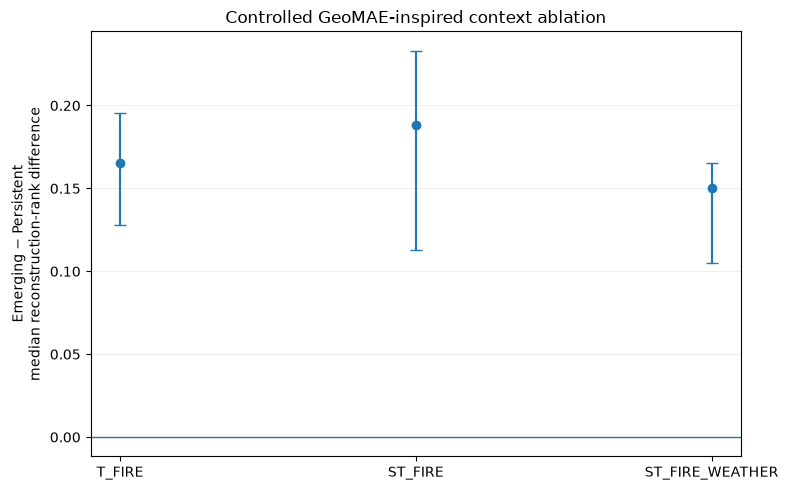

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_anomaly_validation\t2\figures\01_controlled_ablation.png


In [64]:
# 35. Ablation effect plot

if len(
    ablation_bootstrap
):
    plot_df = (
        ablation_bootstrap[
            [
                "variant",
                "observed_median_difference",
                "bootstrap_2.5%",
                "bootstrap_97.5%",
            ]
        ]
        .copy()
    )

    x = np.arange(
        len(plot_df)
    )

    y = plot_df[
        "observed_median_difference"
    ].to_numpy()

    lower = (
        y
        - plot_df[
            "bootstrap_2.5%"
        ].to_numpy()
    )

    upper = (
        plot_df[
            "bootstrap_97.5%"
        ].to_numpy()
        - y
    )

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.errorbar(
        x,
        y,
        yerr=[
            lower,
            upper,
        ],
        fmt="o",
        capsize=4,
    )

    ax.axhline(
        0,
        linewidth=1,
    )

    ax.set_xticks(
        x,
        plot_df["variant"],
    )

    ax.set_ylabel(
        "Emerging − Persistent\nmedian reconstruction-rank difference"
    )

    ax.set_title(
        "Controlled GeoMAE-inspired context ablation"
    )

    ax.grid(
        axis="y",
        alpha=0.2,
    )

    plt.tight_layout()

    path = (
        FIGURE_DIR
        / "01_controlled_ablation.png"
    )

    plt.savefig(
        path,
        dpi=190,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)

# PART H — Decision logic

NB24B does not use one arbitrary pass/fail number for the whole thesis.

Instead, inspect four independent questions.

### A. Masked latent correction
Does the corrected masked-center latent score behave more consistently with contextual anomaly than the unmasked score?

### B. Intensity confounding
Is reconstruction anomaly strongly correlated with fire count / FRP?

More importantly:
- does Emerging remain higher after intensity adjustment?
- does the fire-presence reconstruction component show the same direction?

### C. Redundancy
If GeoMAE reconstruction and history anomaly have near-perfect overlap/correlation,
the Transformer is largely reproducing a hand-crafted rule.

Moderate overlap with interpretable disagreement is more interesting.

### D. Ablation
Interpret the sequence:

`T_FIRE → ST_FIRE → ST_FIRE_WEATHER`

- improvement from T_FIRE to ST_FIRE supports the value of spatial context;
- improvement from ST_FIRE to ST_FIRE_WEATHER supports the value of environmental context;
- no improvement means that component should not be oversold.

Because no ignition-cause ground truth exists, these are **representation-validation claims**,
not claims that the model discovers anthropogenic fire.

In [65]:
# 36. Save outputs

MASKED_LATENT_PATH = (
    EXPORT_DIR
    / "august_masked_center_latent_scores.csv"
)

POSITIVE_VALIDATION_PATH = (
    EXPORT_DIR
    / "august_positive_geomae_validation.csv"
)

LATENT_SUMMARY_PATH = (
    EXPORT_DIR
    / "masked_latent_group_summary.csv"
)

LATENT_BOOTSTRAP_PATH = (
    EXPORT_DIR
    / "masked_latent_bootstrap.csv"
)

INTENSITY_AUDIT_PATH = (
    EXPORT_DIR
    / "intensity_correlation_audit.csv"
)

INTENSITY_SUMMARY_PATH = (
    EXPORT_DIR
    / "intensity_adjusted_group_summary.csv"
)

REDUNDANCY_PATH = (
    EXPORT_DIR
    / "score_spearman_correlation.csv"
)

GEOMAE_SPECIFIC_PATH = (
    EXPORT_DIR
    / "geomae_high_history_not_high.csv"
)

ABLATION_SUMMARY_PATH = (
    EXPORT_DIR
    / "controlled_ablation_group_summary.csv"
)

ABLATION_BOOTSTRAP_PATH = (
    EXPORT_DIR
    / "controlled_ablation_bootstrap.csv"
)

METADATA_PATH = (
    EXPORT_DIR
    / "nb24b_methodology_metadata.json"
)

masked_latent_scores.to_csv(
    MASKED_LATENT_PATH,
    index=False,
)

analysis_positive.to_csv(
    POSITIVE_VALIDATION_PATH,
    index=False,
)

latent_group_summary.to_csv(
    LATENT_SUMMARY_PATH,
    index=False,
)

corrected_latent_bootstrap.to_csv(
    LATENT_BOOTSTRAP_PATH,
    index=False,
)

intensity_correlation_audit.to_csv(
    INTENSITY_AUDIT_PATH,
    index=False,
)

intensity_adjusted_summary.to_csv(
    INTENSITY_SUMMARY_PATH,
    index=False,
)

rank_correlation.to_csv(
    REDUNDANCY_PATH,
)

geomae_specific.to_csv(
    GEOMAE_SPECIFIC_PATH,
    index=False,
)

if len(
    ablation_summary
):
    ablation_summary.to_csv(
        ABLATION_SUMMARY_PATH,
        index=False,
    )

if len(
    ablation_bootstrap
):
    ablation_bootstrap.to_csv(
        ABLATION_BOOTSTRAP_PATH,
        index=False,
    )

metadata = {
    "notebook": "24B_geomae_anomaly_validation",
    "september_used": False,
    "validation_tasks": [
        "masked-center latent correction",
        "fire-intensity confounding audit",
        "hand-crafted anomaly redundancy audit",
        "controlled temporal/spatial/weather ablation",
    ],
    "ablation_variants": {
        name: config["description"]
        for name, config
        in VARIANTS.items()
    },
    "ablation_epochs": ABLATION_EPOCHS,
    "important_limit": (
        "No result is an ignition-cause or anthropogenic-fire ground-truth label."
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_anomaly_validation\t2\exports


In [66]:
# 37. Automatic review summary

print("=== NB24B AUTOMATIC REVIEW ===")
print()

print(
    "Old-unmasked vs corrected-masked latent Spearman:",
    round(
        float(
            rho_old_new
        ),
        4,
    ),
)

print(
    "Reconstruction vs corrected-masked latent Spearman:",
    round(
        float(
            rho_recon_masked_latent
        ),
        4,
    ),
)

print()
print("Corrected latent / reconstruction group summary:")
display(
    latent_group_summary
)

print()
print("Corrected latent bootstrap:")
display(
    corrected_latent_bootstrap
)

print()
print("Intensity correlation audit:")
display(
    intensity_correlation_audit
)

print()
print(
    "Intensity-adjusted reconstruction summary:"
)
display(
    intensity_adjusted_summary
)

print()
print(
    "Intensity-adjusted Emerging-Persistent bootstrap:"
)
display(
    pd.DataFrame(
        [
            intensity_residual_bootstrap
        ]
    )
)

print()
print(
    "GeoMAE reconstruction vs history Top-20% Jaccard:",
    round(
        float(
            history_geomae_jaccard
        ),
        4,
    ),
)

print(
    "High GeoMAE but history < 0.80:",
    len(
        geomae_specific
    ),
)

if len(
    ablation_bootstrap
):
    print()
    print(
        "Controlled ablation Emerging-Persistent differences:"
    )

    display(
        ablation_bootstrap[
            [
                "variant",
                "observed_median_difference",
                "bootstrap_2.5%",
                "bootstrap_97.5%",
            ]
        ]
    )

print()
print(
    "Do not use September for tuning after this notebook."
)

=== NB24B AUTOMATIC REVIEW ===

Old-unmasked vs corrected-masked latent Spearman: 0.8115
Reconstruction vs corrected-masked latent Spearman: 0.3791

Corrected latent / reconstruction group summary:


,research_group,events,reconstruction_rank_mean,reconstruction_rank_median,old_unmasked_latent_rank_median,corrected_masked_latent_rank_mean,corrected_masked_latent_rank_median
0,Emerging-3,217,0.77402,0.819549,0.578947,0.375212,0.353383
1,Persistent,1849,0.58900,0.616541,0.729323,0.641863,0.691729



Corrected latent bootstrap:


,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mae_fire_reconstruction_error__day_rank,0.203008,0.180451,0.225564,2000
1,embedding_knn_distance__day_rank,-0.150376,-0.248214,-0.090226,2000
2,masked_center_knn_distance__day_rank,-0.338346,-0.417293,-0.274436,2000



Intensity correlation audit:


,anomaly_score,intensity_variable,spearman_rho,p_value,n
0,mae_fire_reconstruction_error__day_rank,fire_count_log1p,-0.049150,2.547997e-02,2066
1,mae_fire_reconstruction_error__day_rank,frp_sum_log1p,0.068605,1.807897e-03,2066
2,presence_reconstruction_error__day_rank,fire_count_log1p,-0.671274,9.450489e-271,2066
3,presence_reconstruction_error__day_rank,frp_sum_log1p,-0.560304,4.176553e-171,2066
4,count_reconstruction_error__day_rank,fire_count_log1p,0.229248,4.834060e-26,2066
5,count_reconstruction_error__day_rank,frp_sum_log1p,0.239844,2.030301e-28,2066
6,frp_reconstruction_error__day_rank,fire_count_log1p,0.050539,2.160614e-02,2066
7,frp_reconstruction_error__day_rank,frp_sum_log1p,0.219915,4.795569e-24,2066


... (3 outputs left out)

,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,reconstruction_intensity_residual,0.206227,0.178318,0.232994,2000



GeoMAE reconstruction vs history Top-20% Jaccard: 0.093
High GeoMAE but history < 0.80: 542

Controlled ablation Emerging-Persistent differences:


,variant,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%
0,T_FIRE,0.165414,0.127820,0.195489
1,ST_FIRE,0.187970,0.112782,0.233083
2,ST_FIRE_WEATHER,0.150376,0.105263,0.165414



Do not use September for tuning after this notebook.


# What to send back

After **Run All**, send the executed NB24B notebook.

The key outputs to review are:

1. corrected masked-center latent Emerging vs Persistent summary;
2. corrected latent bootstrap;
3. intensity-correlation table;
4. intensity-adjusted Emerging vs Persistent bootstrap;
5. GeoMAE-vs-history correlation / Top-20% overlap;
6. controlled ablation:
   - `T_FIRE`
   - `ST_FIRE`
   - `ST_FIRE_WEATHER`.

From those results we can make a defensible decision about whether the GeoMAE-inspired method
is genuinely the main contribution of the thesis, and exactly which components deserve to be
claimed as useful.